# EfficientNet + SVM skin lesion classification (ISIC 2019) - revised experiments

Kaggle settings before running: **Accelerator = GPU T4** (one GPU is used), **Internet = On** (timm downloads the ImageNet weights), and add the dataset `salviohexia/isic-2019-skin-lesion-images-for-classification` as input.

Run order: sections 1-3 need no GPU (turn the accelerator off for the DullRazor cache if you want to save GPU hours). Every training run, feature file and prediction file is cached in `/kaggle/working`, so a stopped session can be resumed by re-running the cells.

In [1]:
import copy, json, os, random, time
from multiprocessing import Pool
from pathlib import Path

import cv2
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import timm
import torch
import torch.nn.functional as F
from joblib import Parallel, delayed
from PIL import Image
from scipy.stats import binomtest
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import balanced_accuracy_score, confusion_matrix, f1_score, roc_auc_score
from sklearn.model_selection import ParameterGrid, StratifiedGroupKFold
from sklearn.preprocessing import StandardScaler
from sklearn.svm import SVC
from torch import nn
from torch.utils.data import DataLoader, Dataset, RandomSampler
from torchvision import transforms
from tqdm.auto import tqdm
from xgboost import XGBClassifier

INPUT_ROOT = Path('/kaggle/input')
WORK = Path('/kaggle/working')
CACHE_DIR, RUNS = WORK / 'cache', WORK / 'runs'
for folder in (CACHE_DIR / 'raw', CACHE_DIR / 'clean', RUNS):
    folder.mkdir(parents=True, exist_ok=True)

DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
WORKERS = min(4, os.cpu_count())

CLASS_NAMES = ['AK', 'BCC', 'BKL', 'DF', 'MEL', 'NV', 'SCC', 'VASC']
CLASS_TO_INDEX = {name: index for index, name in enumerate(CLASS_NAMES)}
SPLIT_SEED = 42
SEEDS = [42]
PER_CLASS = 625
EPOCH_SAMPLES = 5000
MAX_EPOCHS, PATIENCE = 30, 6
LEARNING_RATE, WEIGHT_DECAY = 5e-5, 1e-4
CACHE_SIZE = 456

BACKBONES = ['efficientnet_b4', 'efficientnet_b5']
BASELINES = ['resnet50', 'densenet121', 'convnext_tiny', 'swin_tiny_patch4_window7_224']
MODEL_SETTINGS = {
    'efficientnet_b4': (380, 16),
    'efficientnet_b5': (456, 8),
    'resnet50': (224, 64),
    'densenet121': (224, 64),
    'convnext_tiny': (224, 48),
    'swin_tiny_patch4_window7_224': (224, 48),
}
RUN_ABLATIONS, RUN_BASELINES = True, True
EXTERNAL_CSV = None

In [2]:
import shutil
for best in INPUT_ROOT.rglob('best.pth'):
    shutil.copytree(best.parent, RUNS / best.parent.name, dirs_exist_ok=True)
for path in RUNS.glob('*/features_*.npy'):
    path.unlink()
print(len(list(RUNS.glob('*/best.pth'))))

12


## 1. Data and lesion-level split (comments 1, 2)

Labels come from the ground-truth file and `lesion_id` from the metadata file. Images without a `lesion_id` form their own group. The split is made **before** any balancing, grouped by lesion, stratified by class: about 80% train, 10% validation, 10% test. Validation and test keep the **natural class distribution**.

In [3]:
ground_truth = pd.read_csv(next(INPUT_ROOT.rglob('ISIC_2019_Training_GroundTruth.csv')))
metadata = pd.read_csv(next(INPUT_ROOT.rglob('ISIC_2019_Training_Metadata.csv')))
image_paths = {path.stem: path for path in INPUT_ROOT.rglob('ISIC_*.jpg')}

ground_truth = ground_truth[ground_truth[CLASS_NAMES].sum(axis=1) == 1].copy()
ground_truth['label'] = ground_truth[CLASS_NAMES].idxmax(axis=1)
data = ground_truth[['image', 'label']].merge(metadata[['image', 'lesion_id']], on='image')
data = data[data.image.isin(image_paths)].reset_index(drop=True)
data['group'] = data.lesion_id.fillna(data.image)

print(len(data), 'images,', data.group.nunique(), 'groups,', round(data.lesion_id.notna().mean(), 3), 'share with lesion_id')
print(data.label.value_counts())

25331 images, 13931 groups, 0.918 share with lesion_id
label
NV      12875
MEL      4522
BCC      3323
BKL      2624
AK        867
SCC       628
VASC      253
DF        239
Name: count, dtype: int64


In [4]:
def hold_out(frame, folds):
    splitter = StratifiedGroupKFold(n_splits=folds, shuffle=True, random_state=SPLIT_SEED)
    rest, held = next(splitter.split(frame, frame.label, frame.group))
    return frame.iloc[rest].reset_index(drop=True), frame.iloc[held].reset_index(drop=True)

train_val, test = hold_out(data, 10)
train, val = hold_out(train_val, 9)

assert not set(train.group) & set(val.group)
assert not set(train.group) & set(test.group)
assert not set(val.group) & set(test.group)
print(pd.DataFrame({'train': train.label.value_counts(), 'val': val.label.value_counts(), 'test': test.label.value_counts()}).loc[CLASS_NAMES])

y_val = val.label.map(CLASS_TO_INDEX).values
y_test = test.label.map(CLASS_TO_INDEX).values

       train   val  test
label                   
AK       698    67   102
BCC     2581   375   367
BKL     2089   260   275
DF       184    45    10
MEL     3632   425   465
NV     10282  1390  1203
SCC      510    56    62
VASC     221    11    21


## 2. Balancing the training set only (comments 1, 2)

The paper's strategy is kept (random under-sampling above 625 images per class, random over-sampling below) but it is applied to the training split only, per seed. The alternatives use all training images: class-weighted cross-entropy and focal loss (gamma 2, class-weighted). Every strategy sees `EPOCH_SAMPLES` images per epoch so the training budget is equal.

In [5]:
def balanced_frame(frame, per_class, seed):
    parts = [group.sample(per_class, replace=len(group) < per_class, random_state=seed) for _, group in frame.groupby('label')]
    return pd.concat(parts).reset_index(drop=True)

class_weights = torch.tensor(
    len(train) / (len(CLASS_NAMES) * train.label.value_counts()[CLASS_NAMES].values),
    dtype=torch.float32, device=DEVICE)

example = balanced_frame(train, PER_CLASS, SEEDS[0])
print(len(example), 'rows,', example.image.nunique(), 'unique images in the balanced training set')

5000 rows, 3853 unique images in the balanced training set


## 3. DullRazor at native resolution (comment 5)

DullRazor runs on the original 8-bit image (black-hat with a 17x17 rectangular kernel, Otsu threshold, Telea inpainting, radius 3) and the result is then resized. Two caches are written: `clean` (DullRazor on) and `raw` (DullRazor off, for the ablation). Both are resized to 456x456 once; each model resizes from this cache to its own input size.

In [6]:
cv2.setNumThreads(0)

def dull_razor(bgr):
    gray = cv2.cvtColor(bgr, cv2.COLOR_BGR2GRAY)
    black_hat = cv2.morphologyEx(gray, cv2.MORPH_BLACKHAT, cv2.getStructuringElement(cv2.MORPH_RECT, (17, 17)))
    _, mask = cv2.threshold(black_hat, 0, 255, cv2.THRESH_BINARY | cv2.THRESH_OTSU)
    return cv2.inpaint(bgr, mask, 3, cv2.INPAINT_TELEA)

def cache_image(image_id):
    clean_path, raw_path = CACHE_DIR / 'clean' / f'{image_id}.jpg', CACHE_DIR / 'raw' / f'{image_id}.jpg'
    if clean_path.exists() and raw_path.exists():
        return
    bgr = cv2.imread(str(image_paths[image_id]))
    for path, image in ((raw_path, bgr), (clean_path, dull_razor(bgr))):
        resized = cv2.resize(image, (CACHE_SIZE, CACHE_SIZE), interpolation=cv2.INTER_AREA)
        cv2.imwrite(str(path), resized, [cv2.IMWRITE_JPEG_QUALITY, 95])

needed = pd.concat([balanced_frame(train, PER_CLASS, seed) for seed in SEEDS] + [val, test]).image.unique()
with Pool(os.cpu_count()) as pool:
    list(tqdm(pool.imap_unordered(cache_image, needed.tolist(), chunksize=16), total=len(needed)))

  0%|          | 0/8987 [00:00<?, ?it/s]

## 4. Models, training and metrics (comments 4, 6, 7)

All backbones are fine-tuned end to end from ImageNet weights at their native input size (EfficientNet-B4 380, B5 456, the others 224) with AdamW, `ReduceLROnPlateau`, mixed precision and early stopping on **validation balanced accuracy**. Augmentation (horizontal flip, rotation up to 30 degrees) is applied to the training split only.

Metrics: accuracy, balanced accuracy, macro-F1, macro one-vs-rest ROC-AUC computed from class probabilities, expected calibration error (15 bins), and per-class sensitivity and specificity. Features are always taken from a **copy** of the model with the head removed, so the softmax models used for the ROC curves are never modified.

In [7]:
class LesionImages(Dataset):
    def __init__(self, frame, variant, size, augment=False):
        self.ids = frame.image.tolist()
        self.labels = frame.label.map(CLASS_TO_INDEX).tolist()
        self.folder = CACHE_DIR / variant
        steps = [transforms.Resize((size, size))]
        if augment:
            steps += [transforms.RandomHorizontalFlip(), transforms.RandomRotation(30)]
        steps += [transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])]
        self.transform = transforms.Compose(steps)

    def __len__(self):
        return len(self.ids)

    def __getitem__(self, index):
        image = Image.open(self.folder / f'{self.ids[index]}.jpg').convert('RGB')
        return self.transform(image), self.labels[index]

def make_loader(frame, variant, size, batch_size):
    return DataLoader(LesionImages(frame, variant, size), batch_size=batch_size, shuffle=False, num_workers=WORKERS, pin_memory=True)

def build(name):
    return timm.create_model(name, pretrained=False, num_classes=len(CLASS_NAMES)).to(DEVICE)

@torch.no_grad()
def predict(model, loader):
    model.eval()
    outputs, targets = [], []
    for images, labels in loader:
        with torch.autocast('cuda'):
            outputs.append(model(images.to(DEVICE, non_blocking=True)).float().cpu())
        targets.append(labels)
    return torch.cat(outputs), torch.cat(targets).numpy()

def softmax(logits):
    return torch.softmax(logits.double(), dim=1).numpy()

def focal_loss(logits, targets, weight, gamma=2.0):
    log_prob = F.log_softmax(logits, dim=1).gather(1, targets[:, None])[:, 0]
    return -(weight[targets] * (1 - log_prob.exp()) ** gamma * log_prob).mean()

def calibration_bins(y, probs, bins=15):
    confidence, correct = probs.max(1), probs.argmax(1) == y
    index = np.digitize(confidence, np.linspace(0, 1, bins + 1)[1:-1])
    used = [b for b in range(bins) if (index == b).any()]
    return (np.array([confidence[index == b].mean() for b in used]),
            np.array([correct[index == b].mean() for b in used]),
            np.array([(index == b).mean() for b in used]))

def summary(y, probs):
    prediction = probs.argmax(1)
    confidence, accuracy, weight = calibration_bins(y, probs)
    return {
        'accuracy': (prediction == y).mean(),
        'balanced_accuracy': balanced_accuracy_score(y, prediction),
        'macro_f1': f1_score(y, prediction, average='macro'),
        'macro_auc_ovr': roc_auc_score(y, probs, multi_class='ovr', average='macro', labels=list(range(len(CLASS_NAMES)))),
        'ece': (weight * abs(accuracy - confidence)).sum(),
    }

def per_class(y, probs):
    matrix = confusion_matrix(y, probs.argmax(1), labels=list(range(len(CLASS_NAMES))))
    tp = np.diag(matrix)
    fn, fp = matrix.sum(1) - tp, matrix.sum(0) - tp
    tn = matrix.sum() - tp - fn - fp
    return pd.DataFrame({'sensitivity': tp / (tp + fn), 'specificity': tn / (tn + fp)}, index=CLASS_NAMES)

In [8]:
def run(name, variant, strategy, seed):
    size, batch_size = MODEL_SETTINGS[name]
    run_dir = RUNS / f'{name}_{variant}_{strategy}_s{seed}'
    run_dir.mkdir(exist_ok=True)
    best_path, preds_path = run_dir / 'best.pth', run_dir / 'preds.npz'
    if preds_path.exists():
        saved = np.load(preds_path)
        return saved['val'], saved['test']

    val_loader = make_loader(val, variant, size, batch_size * 2)
    if not best_path.exists():
        assert DEVICE.type == 'cuda', 'enable the GPU accelerator'
        random.seed(seed); np.random.seed(seed); torch.manual_seed(seed)
        train_rows = balanced_frame(train, PER_CLASS, seed) if strategy == 'resample' else train
        train_set = LesionImages(train_rows, variant, size, augment=True)
        sampler = None if strategy == 'resample' else RandomSampler(train_set, num_samples=EPOCH_SAMPLES)
        train_loader = DataLoader(train_set, batch_size=batch_size, shuffle=sampler is None, sampler=sampler,
                                  num_workers=WORKERS, pin_memory=True, drop_last=True)
        criterion = {
            'resample': nn.CrossEntropyLoss(),
            'weighted': nn.CrossEntropyLoss(weight=class_weights),
            'focal': lambda logits, targets: focal_loss(logits, targets, class_weights),
        }[strategy]
        model = timm.create_model(name, pretrained=True, num_classes=len(CLASS_NAMES)).to(DEVICE)
        optimizer = torch.optim.AdamW(model.parameters(), lr=LEARNING_RATE, weight_decay=WEIGHT_DECAY)
        scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer, mode='max', factor=0.5, patience=2)
        scaler = torch.amp.GradScaler('cuda')
        best_score, stale, history = -1.0, 0, []

        for epoch in range(MAX_EPOCHS):
            model.train()
            started, running = time.time(), 0.0
            for images, targets in train_loader:
                images, targets = images.to(DEVICE, non_blocking=True), targets.to(DEVICE, non_blocking=True)
                optimizer.zero_grad(set_to_none=True)
                with torch.autocast('cuda'):
                    logits = model(images)
                loss = criterion(logits.float(), targets)
                scaler.scale(loss).backward()
                scaler.step(optimizer)
                scaler.update()
                running += loss.item()
            val_logits, _ = predict(model, val_loader)
            val_score = balanced_accuracy_score(y_val, val_logits.argmax(1).numpy())
            scheduler.step(val_score)
            history.append({'epoch': epoch + 1, 'train_loss': running / len(train_loader), 'val_balanced_accuracy': val_score})
            print(f'{run_dir.name} | epoch {epoch + 1} | loss {running / len(train_loader):.4f} | val bal.acc {val_score:.4f} | {time.time() - started:.0f}s')
            if val_score > best_score:
                best_score, stale = val_score, 0
                torch.save(model.state_dict(), best_path)
            else:
                stale += 1
                if stale >= PATIENCE:
                    break
        json.dump(history, open(run_dir / 'history.json', 'w'))
        del model, optimizer

    model = build(name)
    model.load_state_dict(torch.load(best_path, map_location=DEVICE))
    val_prob = softmax(predict(model, val_loader)[0])
    test_prob = softmax(predict(model, make_loader(test, variant, size, batch_size * 2))[0])
    np.savez(preds_path, val=val_prob, test=test_prob)
    return val_prob, test_prob

## 5. Training runs (comments 2, 3, 7, 8)

- Main: EfficientNet-B4 and B5, DullRazor on, resampled training set, one run per seed in `SEEDS`.
- Ablations (first seed): DullRazor off; all images with class-weighted loss; all images with focal loss.
- Baselines (first seed, same split and recipe, native resolution): ResNet50, DenseNet121, ConvNeXt-T, Swin-T.

Set `RUN_ABLATIONS` / `RUN_BASELINES` to `False` or edit `SEEDS` in the first cell to change the budget.

In [9]:
runs = [(name, 'clean', 'resample', seed) for seed in SEEDS for name in BACKBONES]
if RUN_ABLATIONS:
    runs += [(name, variant, strategy, SEEDS[0]) for name in BACKBONES
             for variant, strategy in [('raw', 'resample'), ('clean', 'weighted'), ('clean', 'focal')]]
if RUN_BASELINES:
    runs += [(name, 'clean', 'resample', SEEDS[0]) for name in BASELINES]

val_probs, test_probs = {}, {}
for name, variant, strategy, seed in runs:
    key = (f'{name}|{variant}|{strategy}', seed)
    val_probs[key], test_probs[key] = run(name, variant, strategy, seed)
    print(key, {metric: round(float(value), 4) for metric, value in summary(y_test, test_probs[key]).items()})

('efficientnet_b4|clean|resample', 42) {'accuracy': 0.6391, 'balanced_accuracy': 0.5145, 'macro_f1': 0.4527, 'macro_auc_ovr': 0.8962, 'ece': 0.1486}
('efficientnet_b5|clean|resample', 42) {'accuracy': 0.677, 'balanced_accuracy': 0.5542, 'macro_f1': 0.5029, 'macro_auc_ovr': 0.8991, 'ece': 0.2231}
('efficientnet_b4|raw|resample', 42) {'accuracy': 0.6048, 'balanced_accuracy': 0.52, 'macro_f1': 0.4346, 'macro_auc_ovr': 0.896, 'ece': 0.1179}
('efficientnet_b4|clean|weighted', 42) {'accuracy': 0.6551, 'balanced_accuracy': 0.5448, 'macro_f1': 0.4713, 'macro_auc_ovr': 0.9119, 'ece': 0.0636}
('efficientnet_b4|clean|focal', 42) {'accuracy': 0.6028, 'balanced_accuracy': 0.5509, 'macro_f1': 0.4371, 'macro_auc_ovr': 0.8904, 'ece': 0.0638}
('efficientnet_b5|raw|resample', 42) {'accuracy': 0.6978, 'balanced_accuracy': 0.627, 'macro_f1': 0.5711, 'macro_auc_ovr': 0.929, 'ece': 0.2212}
('efficientnet_b5|clean|weighted', 42) {'accuracy': 0.7238, 'balanced_accuracy': 0.6143, 'macro_f1': 0.5629, 'macro_auc

## 6. Hybrid EfficientNet + SVM (comments 4, 6)

Pipeline: the fine-tuned B4 and B5 backbones are frozen, the pooled feature vectors (1792-d for B4, 2048-d for B5, each at its native input size) are concatenated into a 3840-d vector, standardised with a scaler fitted on the training features, and classified by the SVM. Features come from the same training rows the backbones were trained on (the resampled training split), and from the untouched validation and test splits.

SVM probabilities come from scikit-learn's Platt scaling (internal 5-fold fit on the training features). Metrics use `argmax(predict_proba)` for every model; the agreement with `predict` is printed.

In [10]:
@torch.no_grad()
def predict(model, loader, half=True):
    model.eval()
    outputs, targets = [], []
    for images, labels in loader:
        with torch.autocast('cuda', enabled=half):
            outputs.append(model(images.to(DEVICE, non_blocking=True)).float().cpu())
        targets.append(labels)
    return torch.cat(outputs), torch.cat(targets).numpy()

def features_for(name, seed, split_name, rows):
    path = RUNS / f'{name}_clean_resample_s{seed}' / f'features_{split_name}.npy'
    if path.exists():
        return np.load(path)
    size, batch_size = MODEL_SETTINGS[name]
    extractor = build(name)
    extractor.load_state_dict(torch.load(RUNS / f'{name}_clean_resample_s{seed}' / 'best.pth', map_location=DEVICE))
    extractor.reset_classifier(0)
    features, _ = predict(extractor, make_loader(rows, 'clean', size, batch_size * 2), half=False)
    np.save(path, features.numpy())
    return features.numpy()

hybrid = {}
for seed in SEEDS:
    rows = {'train': balanced_frame(train, PER_CLASS, seed), 'val': val, 'test': test}
    fused = {split: np.hstack([features_for(name, seed, split, frame) for name in BACKBONES]) for split, frame in rows.items()}
    for split, values in fused.items():
        print(seed, split, values.shape, 'non-finite values:', int((~np.isfinite(values)).sum()))
    assert all(np.isfinite(values).all() for values in fused.values())
    scaler = StandardScaler().fit(fused['train'])
    hybrid[seed] = {
        'scaler': scaler,
        'x': {split: scaler.transform(values).astype(np.float32) for split, values in fused.items()},
        'y': {split: frame.label.map(CLASS_TO_INDEX).values for split, frame in rows.items()},
    }

42 train (5000, 3840) non-finite values: 0
42 val (2629, 3840) non-finite values: 0
42 test (2505, 3840) non-finite values: 0


## 7. Classifier comparison and SVM tuning (comments 3, 9)

Each classifier is tuned on the validation split (balanced accuracy) over a small grid, then refitted on the training features. Nothing is tuned on the test split. The SVM grid extends C to 1000 so the optimum is no longer at the edge, and gamma is varied numerically (after standardisation `scale` and `auto` are the same value, 1/n_features). The softmax heads of B4 and B5 and their mean are added for comparison. Full grid search over the CNN hyperparameters was not run; only the SVM and the other classifiers on the features are tuned.

In [11]:
fitted, tuned = {}, {}
for seed in SEEDS:
    x, y = hybrid[seed]['x'], hybrid[seed]['y']
    base_gamma = 1 / x['train'].shape[1]
    specs = {
        'SVM-RBF': (lambda **p: SVC(kernel='rbf', random_state=seed, **p),
                    {'C': [0.1, 1, 10, 100, 1000], 'gamma': [base_gamma * m for m in (0.1, 1, 10)]}, WORKERS),
        'SVM-linear': (lambda **p: SVC(kernel='linear', random_state=seed, **p), {'C': [0.001, 0.01, 0.1, 1]}, WORKERS),
        'LogReg': (lambda **p: LogisticRegression(max_iter=3000, **p), {'C': [0.01, 0.1, 1, 10]}, WORKERS),
        'RandomForest': (lambda **p: RandomForestClassifier(n_estimators=500, n_jobs=1, random_state=seed, **p),
                         {'max_features': ['sqrt', 'log2']}, WORKERS),
        'XGBoost': (lambda **p: XGBClassifier(n_estimators=300, tree_method='hist', device='cuda', random_state=seed, **p),
                    {'max_depth': [3, 6], 'learning_rate': [0.05, 0.1]}, 1),
    }
    if seed != SEEDS[0]:
        specs = {'SVM-RBF': (specs['SVM-RBF'][0], {key: [value] for key, value in tuned['SVM-RBF'].items()}, 1)}

    for label, (factory, grid, jobs) in specs.items():
        scored = Parallel(n_jobs=jobs)(
            delayed(lambda p: (balanced_accuracy_score(y['val'], factory(**p).fit(x['train'], y['train']).predict(x['val'])), p))(params)
            for params in ParameterGrid(grid))
        best_score, best_params = max(scored, key=lambda item: item[0])
        classifier = factory(**best_params)
        if 'probability' in classifier.get_params():
            classifier.set_params(probability=True)
        classifier.fit(x['train'], y['train'])
        fitted[(label, seed)], tuned[label] = classifier, best_params
        test_probs[(f'hybrid {label}|clean|resample', seed)] = classifier.predict_proba(x['test'])
        print(seed, label, best_params, 'val bal.acc', round(best_score, 4))

    svm = fitted[('SVM-RBF', seed)]
    print('SVM-RBF train accuracy', svm.score(x['train'], y['train']),
          '| predict vs argmax(predict_proba) agreement', (svm.predict(x['test']) == svm.predict_proba(x['test']).argmax(1)).mean())

for seed in SEEDS:
    test_probs[('B4+B5 softmax mean|clean|resample', seed)] = (
        test_probs[('efficientnet_b4|clean|resample', seed)] + test_probs[('efficientnet_b5|clean|resample', seed)]) / 2

42 SVM-RBF {'C': 0.1, 'gamma': 0.00026041666666666666} val bal.acc 0.5727
42 SVM-linear {'C': 0.001} val bal.acc 0.5497
42 LogReg {'C': 0.01} val bal.acc 0.5663
42 RandomForest {'max_features': 'sqrt'} val bal.acc 0.5673


/usr/local/lib/python3.13/dist-packages/xgboost/core.py:569: UserWarning: [11:39:55] WARNING: /__w/xgboost/xgboost/src/common/error_msg.cc:62: Falling back to prediction using DMatrix due to mismatched devices. This might lead to higher memory usage and slower performance. XGBoost is running on: cuda:0, while the input data is on: cpu.
Potential solutions:
- Use a data structure that matches the device ordinal in the booster.
- Set the device for booster before call to inplace_predict.

This warning will only be shown once.

  return func(**kwargs)


42 XGBoost {'learning_rate': 0.1, 'max_depth': 6} val bal.acc 0.5489
SVM-RBF train accuracy 0.9956 | predict vs argmax(predict_proba) agreement 0.9568862275449102


## 8. Results on the natural-distribution test set (comments 2, 3, 4, 10)

In [12]:
results = pd.DataFrame({f'{label} (seed {seed})': summary(y_test, probs) for (label, seed), probs in test_probs.items()}).T.round(4)
results.to_csv(WORK / 'results_test.csv')
results

,accuracy,balanced_accuracy,macro_f1,macro_auc_ovr,ece
efficientnet_b4|clean|resample (seed 42),0.6391,0.5145,0.4527,0.8962,0.1486
efficientnet_b5|clean|resample (seed 42),0.6770,0.5542,0.5029,0.8991,0.2231
efficientnet_b4|raw|resample (seed 42),0.6048,0.5200,0.4346,0.8960,0.1179
efficientnet_b4|clean|weighted (seed 42),0.6551,0.5448,0.4713,0.9119,0.0636
efficientnet_b4|clean|focal (seed 42),0.6028,0.5509,0.4371,0.8904,0.0638
efficientnet_b5|raw|resample (seed 42),0.6978,0.6270,0.5711,0.9290,0.2212
efficientnet_b5|clean|weighted (seed 42),0.7238,0.6143,0.5629,0.9339,0.1091
efficientnet_b5|clean|focal (seed 42),0.7062,0.6330,0.5206,0.9241,0.0320
resnet50|clean|resample (seed 42),0.5904,0.5125,0.4240,0.8791,0.0632
densenet121|clean|resample (seed 42),0.6104,0.5232,0.4460,0.8771,0.0788


                      sensitivity  specificity
B4 softmax       MEL       0.5505       0.9137
                 NV        0.7564       0.8886
B5 softmax       MEL       0.6344       0.8892
                 NV        0.7697       0.8986
Hybrid (SVM-RBF) MEL       0.6688       0.8877
                 NV        0.7772       0.9178


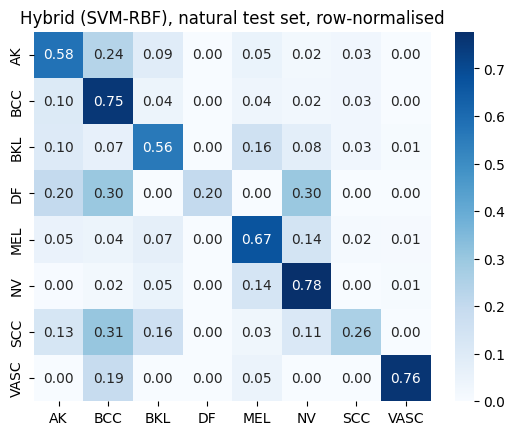

In [13]:
main_seed = SEEDS[0]
focus = {
    'B4 softmax': 'efficientnet_b4|clean|resample',
    'B5 softmax': 'efficientnet_b5|clean|resample',
    'Hybrid (SVM-RBF)': 'hybrid SVM-RBF|clean|resample',
}
sens_spec = pd.concat({title: per_class(y_test, test_probs[(key, main_seed)]).loc[['MEL', 'NV']] for title, key in focus.items()}).round(4)
sens_spec.to_csv(WORK / 'melanoma_nv_sensitivity_specificity.csv')
print(sens_spec)

matrix = confusion_matrix(y_test, test_probs[(focus['Hybrid (SVM-RBF)'], main_seed)].argmax(1), normalize='true')
sns.heatmap(matrix, annot=True, fmt='.2f', xticklabels=CLASS_NAMES, yticklabels=CLASS_NAMES, cmap='Blues')
plt.title('Hybrid (SVM-RBF), natural test set, row-normalised')
plt.savefig(WORK / 'confusion_hybrid.png', dpi=200, bbox_inches='tight')
plt.show()

## 8b. Classification reports, ROC curves and train vs test accuracy (replaces the old Figs. 4, 6-9)

Train accuracy is measured on the resampled training rows with no augmentation; test accuracy is on the natural-distribution test set.

B4 softmax
              precision  recall  f1-score   support
AK                0.280   0.588     0.380   102.000
BCC               0.689   0.567     0.622   367.000
BKL               0.401   0.498     0.444   275.000
DF                0.054   0.200     0.085    10.000
MEL               0.593   0.551     0.571   465.000
NV                0.863   0.756     0.806  1203.000
SCC               0.140   0.194     0.162    62.000
VASC              0.432   0.762     0.552    21.000
accuracy          0.639   0.639     0.639     0.639
macro avg         0.431   0.514     0.453  2505.000
weighted avg      0.688   0.639     0.657  2505.000
B5 softmax
              precision  recall  f1-score   support
AK                0.307   0.598     0.405   102.000
BCC               0.693   0.659     0.676   367.000
BKL               0.486   0.505     0.496   275.000
DF                0.154   0.200     0.174    10.000
MEL               0.566   0.634     0.598   465.000
NV                0.875   0.770     0.819 

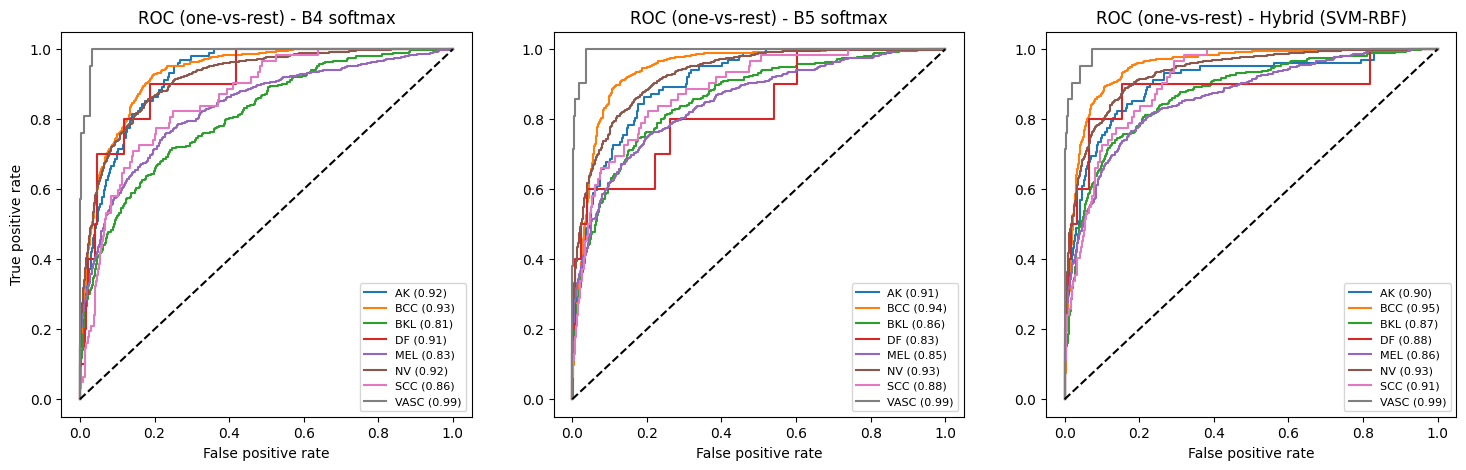

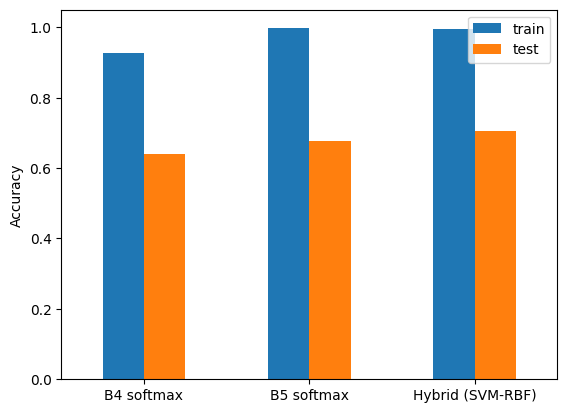

,train,test
B4 softmax,0.9282,0.6391
B5 softmax,0.9990,0.6770
Hybrid (SVM-RBF),0.9956,0.7066


In [14]:
from sklearn.metrics import classification_report, roc_curve, auc

for title, key in focus.items():
    report = pd.DataFrame(classification_report(y_test, test_probs[(key, main_seed)].argmax(1), target_names=CLASS_NAMES, output_dict=True)).T.round(3)
    report.to_csv(WORK / f'classification_report_{title.split()[0].lower()}.csv')
    print(title)
    print(report)

fig, axes = plt.subplots(1, 3, figsize=(18, 5))
for axis, (title, key) in zip(axes, focus.items()):
    probs = test_probs[(key, main_seed)]
    for index, class_name in enumerate(CLASS_NAMES):
        fpr, tpr, _ = roc_curve(y_test == index, probs[:, index])
        axis.plot(fpr, tpr, label=f'{class_name} ({auc(fpr, tpr):.2f})')
    axis.plot([0, 1], [0, 1], 'k--')
    axis.set_title(f'ROC (one-vs-rest) - {title}')
    axis.set_xlabel('False positive rate')
    axis.legend(loc='lower right', fontsize=8)
axes[0].set_ylabel('True positive rate')
plt.savefig(WORK / 'roc_curves.png', dpi=200, bbox_inches='tight')
plt.show()

train_rows = balanced_frame(train, PER_CLASS, main_seed)
y_train_rows = train_rows.label.map(CLASS_TO_INDEX).values
accuracy_table = {}
for title, name in [('B4 softmax', 'efficientnet_b4'), ('B5 softmax', 'efficientnet_b5')]:
    size, batch_size = MODEL_SETTINGS[name]
    model = build(name)
    model.load_state_dict(torch.load(RUNS / f'{name}_clean_resample_s{main_seed}' / 'best.pth', map_location=DEVICE))
    train_logits, _ = predict(model, make_loader(train_rows, 'clean', size, batch_size * 2))
    accuracy_table[title] = {'train': (train_logits.argmax(1).numpy() == y_train_rows).mean(),
                             'test': (test_probs[(focus[title], main_seed)].argmax(1) == y_test).mean()}
    del model
svm = fitted[('SVM-RBF', main_seed)]
accuracy_table['Hybrid (SVM-RBF)'] = {
    'train': svm.score(hybrid[main_seed]['x']['train'], hybrid[main_seed]['y']['train']),
    'test': (test_probs[(focus['Hybrid (SVM-RBF)'], main_seed)].argmax(1) == y_test).mean()}
accuracy_table = pd.DataFrame(accuracy_table).T.round(4)
accuracy_table.to_csv(WORK / 'train_vs_test_accuracy.csv')
accuracy_table.plot.bar(rot=0, ylim=(0, 1.05))
plt.ylabel('Accuracy')
plt.savefig(WORK / 'train_vs_test_accuracy.png', dpi=200, bbox_inches='tight')
plt.show()
accuracy_table

## 9. Statistical validation (comment 8)

Bootstrap 95% confidence intervals (1000 resamples of the test set), McNemar exact tests for hybrid vs B5 and vs B4, and mean ± SD over the seeds in `SEEDS`.

In [15]:
rng = np.random.default_rng(SPLIT_SEED)
draws = rng.integers(0, len(y_test), (1000, len(y_test)))

def bootstrap_ci(probs):
    prediction = probs.argmax(1)
    stats = np.array([[balanced_accuracy_score(y_test[i], prediction[i]), f1_score(y_test[i], prediction[i], average='macro')] for i in draws])
    return np.percentile(stats, [2.5, 97.5], axis=0)

rows = {}
for title, key in focus.items():
    probs = test_probs[(key, main_seed)]
    (bal_low, f1_low), (bal_high, f1_high) = bootstrap_ci(probs)
    rows[title] = {'balanced_accuracy': round(balanced_accuracy_score(y_test, probs.argmax(1)), 4),
                   'bal_acc 95% CI': f'[{bal_low:.4f}, {bal_high:.4f}]',
                   'macro_f1': round(f1_score(y_test, probs.argmax(1), average='macro'), 4),
                   'macro_f1 95% CI': f'[{f1_low:.4f}, {f1_high:.4f}]'}
print(pd.DataFrame(rows).T)

hybrid_correct = test_probs[(focus['Hybrid (SVM-RBF)'], main_seed)].argmax(1) == y_test
for title in ('B5 softmax', 'B4 softmax'):
    other_correct = test_probs[(focus[title], main_seed)].argmax(1) == y_test
    only_hybrid, only_other = (hybrid_correct & ~other_correct).sum(), (~hybrid_correct & other_correct).sum()
    print(f'McNemar hybrid vs {title}: hybrid-only correct {only_hybrid}, {title}-only correct {only_other}, '
          f'p = {binomtest(int(only_hybrid), int(only_hybrid + only_other), 0.5).pvalue:.4g}')

if len(SEEDS) > 1:
    table = {}
    for title, key in focus.items():
        scores = pd.DataFrame([summary(y_test, test_probs[(key, seed)]) for seed in SEEDS])
        table[title] = {metric: f'{scores[metric].mean():.4f} ± {scores[metric].std():.4f}' for metric in scores}
    print(pd.DataFrame(table).T)

                 balanced_accuracy    bal_acc 95% CI macro_f1  \
B4 softmax                  0.5145  [0.4687, 0.5637]   0.4527   
B5 softmax                  0.5542  [0.5121, 0.6007]   0.5029   
Hybrid (SVM-RBF)            0.5699  [0.5244, 0.6170]   0.5422   

                   macro_f1 95% CI  
B4 softmax        [0.4210, 0.4814]  
B5 softmax        [0.4647, 0.5382]  
Hybrid (SVM-RBF)  [0.4909, 0.5886]  
McNemar hybrid vs B5 softmax: hybrid-only correct 193, B5 softmax-only correct 119, p = 3.311e-05
McNemar hybrid vs B4 softmax: hybrid-only correct 322, B4 softmax-only correct 153, p = 6.639e-15


## 10. Calibration, inference cost, Grad-CAM and misclassified lesions (comment 10)

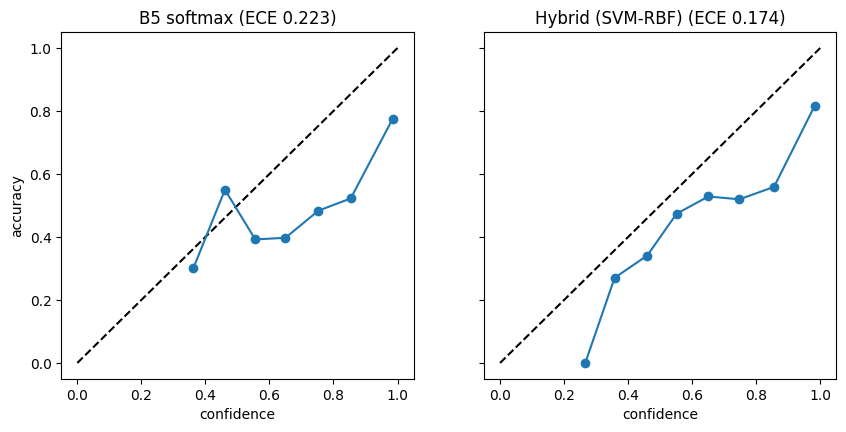

In [16]:
fig, axes = plt.subplots(1, 2, figsize=(10, 4.5), sharey=True)
for axis, (title, key) in zip(axes, [(t, k) for t, k in focus.items() if t != 'B4 softmax']):
    confidence, accuracy, weight = calibration_bins(y_test, test_probs[(key, main_seed)], bins=10)
    axis.plot([0, 1], [0, 1], 'k--')
    axis.plot(confidence, accuracy, 'o-')
    axis.set_title(f'{title} (ECE {(weight * abs(accuracy - confidence)).sum():.3f})')
    axis.set_xlabel('confidence')
axes[0].set_ylabel('accuracy')
plt.savefig(WORK / 'calibration.png', dpi=200, bbox_inches='tight')
plt.show()

In [17]:
timing = {}
sample = test.iloc[:100]
for name in BACKBONES:
    size, _ = MODEL_SETTINGS[name]
    model = build(name)
    model.load_state_dict(torch.load(RUNS / f'{name}_clean_resample_s{main_seed}' / 'best.pth', map_location=DEVICE))
    model.eval()
    torch.cuda.reset_peak_memory_stats()
    elapsed = []
    with torch.no_grad():
        for images, _ in make_loader(sample, 'clean', size, 1):
            images = images.to(DEVICE)
            torch.cuda.synchronize()
            started = time.perf_counter()
            model(images)
            torch.cuda.synchronize()
            elapsed.append(time.perf_counter() - started)
    timing[name] = {'ms_per_image': 1000 * np.median(elapsed[10:]),
                    'peak_gpu_mb': torch.cuda.max_memory_allocated() / 2**20,
                    'parameters_millions': sum(p.numel() for p in model.parameters()) / 1e6}
    del model

svm = fitted[('SVM-RBF', main_seed)]
batch = hybrid[main_seed]['x']['test'][:100]
started = time.perf_counter()
svm.predict_proba(batch)
timing['svm_on_fused_features'] = {'ms_per_image': 1000 * (time.perf_counter() - started) / len(batch)}
pd.DataFrame(timing).T.round(2)

,ms_per_image,peak_gpu_mb,parameters_millions
efficientnet_b4,20.30,129.56,17.56
efficientnet_b5,23.63,194.12,28.36
svm_on_fused_features,16.12,NaN,NaN


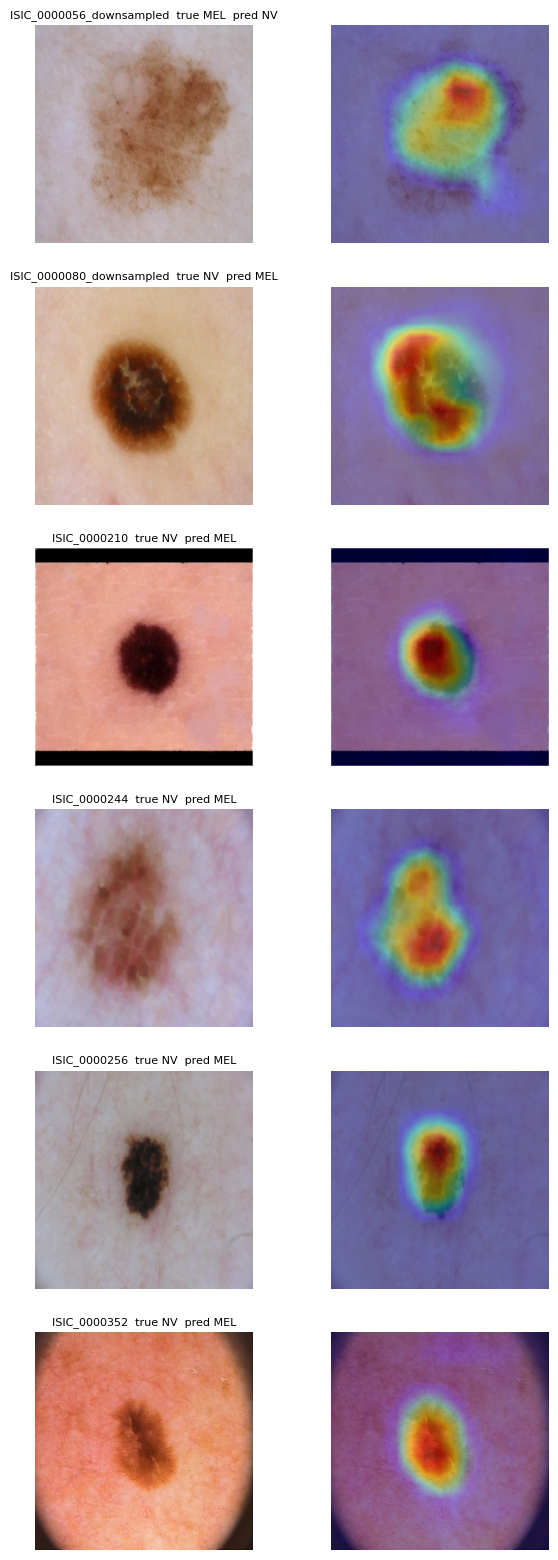

In [18]:
def grad_cam(model, tensor, class_index):
    store = {}
    def hook(module, inputs, output):
        store['activation'] = output
        output.register_hook(lambda grad: store.__setitem__('gradient', grad))
    handle = model.bn2.register_forward_hook(hook)
    model.zero_grad()
    model(tensor[None].to(DEVICE))[0, class_index].backward()
    handle.remove()
    weights = store['gradient'].mean(dim=(2, 3), keepdim=True)
    cam = F.relu((weights * store['activation']).sum(1, keepdim=True))
    cam = F.interpolate(cam, size=tensor.shape[1:], mode='bilinear', align_corners=False)[0, 0].detach().cpu().numpy()
    return (cam - cam.min()) / (cam.max() - cam.min() + 1e-8)

size, _ = MODEL_SETTINGS['efficientnet_b5']
cam_model = build('efficientnet_b5')
cam_model.load_state_dict(torch.load(RUNS / f'efficientnet_b5_clean_resample_s{main_seed}' / 'best.pth', map_location=DEVICE))
cam_model.eval()

predicted = test_probs[(focus['B5 softmax'], main_seed)].argmax(1)
confused = [i for i in np.where(predicted != y_test)[0]
            if {CLASS_NAMES[y_test[i]], CLASS_NAMES[predicted[i]]} == {'MEL', 'NV'}][:6]
test_set = LesionImages(test, 'clean', size)

fig, axes = plt.subplots(len(confused), 2, figsize=(7, 3.3 * len(confused)), squeeze=False)
for row, index in enumerate(confused):
    tensor, _ = test_set[index]
    cam = grad_cam(cam_model, tensor, int(predicted[index]))
    image = Image.open(CACHE_DIR / 'clean' / f'{test.image[index]}.jpg').resize((size, size))
    axes[row, 0].imshow(image)
    axes[row, 1].imshow(image)
    axes[row, 1].imshow(cam, cmap='jet', alpha=0.4)
    axes[row, 0].set_title(f'{test.image[index]}  true {CLASS_NAMES[y_test[index]]}  pred {CLASS_NAMES[predicted[index]]}', fontsize=8)
    for axis in axes[row]:
        axis.axis('off')
plt.savefig(WORK / 'gradcam_misclassified_mel_nv.png', dpi=200, bbox_inches='tight')
plt.show()

## 11. External validation (comment 9)

Attach an external dermoscopy dataset (for example PH2 or Derm7pt) as a Kaggle input, build a CSV with columns `path` and `label` (labels from `AK, BCC, BKL, DF, MEL, NV, SCC, VASC`), and set `EXTERNAL_CSV` in the first cell. Images are passed through the same DullRazor, resize and normalisation. Probabilities are restricted to the classes present in the external set before taking the arg-max.

In [19]:
if EXTERNAL_CSV and Path(EXTERNAL_CSV).exists():
    external = pd.read_csv(EXTERNAL_CSV)
    y_external = external.label.map(CLASS_TO_INDEX).values
    present = np.array(sorted(set(y_external)))

    class ExternalImages(Dataset):
        def __init__(self, size):
            self.size = size
            self.transform = transforms.Compose([transforms.Resize((size, size)), transforms.ToTensor(),
                                                 transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])
        def __len__(self):
            return len(external)
        def __getitem__(self, index):
            cleaned = dull_razor(cv2.imread(external.path[index]))
            rgb = cv2.cvtColor(cv2.resize(cleaned, (CACHE_SIZE, CACHE_SIZE), interpolation=cv2.INTER_AREA), cv2.COLOR_BGR2RGB)
            return self.transform(Image.fromarray(rgb)), y_external[index]

    external_logits, external_features = {}, []
    for name in BACKBONES:
        size, batch_size = MODEL_SETTINGS[name]
        loader = DataLoader(ExternalImages(size), batch_size=batch_size * 2, num_workers=WORKERS)
        model = build(name)
        model.load_state_dict(torch.load(RUNS / f'{name}_clean_resample_s{main_seed}' / 'best.pth', map_location=DEVICE))
        external_logits[name] = softmax(predict(model, loader)[0])
        model.reset_classifier(0)
        external_features.append(predict(model, loader)[0].numpy())

    candidates = {
        'B4 softmax': external_logits['efficientnet_b4'],
        'B5 softmax': external_logits['efficientnet_b5'],
        'Hybrid (SVM-RBF)': fitted[('SVM-RBF', main_seed)].predict_proba(
            hybrid[main_seed]['scaler'].transform(np.hstack(external_features))),
    }
    for title, probs in candidates.items():
        prediction = present[probs[:, present].argmax(1)]
        print(title, 'balanced accuracy', round(balanced_accuracy_score(y_external, prediction), 4),
              '| accuracy', round((prediction == y_external).mean(), 4))

## 12. Split lists and seeds (minor comment)

In [20]:
split_dir = WORK / 'splits'
split_dir.mkdir(exist_ok=True)
for split_name, frame in {'train_natural': train, 'val': val, 'test': test}.items():
    frame.to_csv(split_dir / f'{split_name}.csv', index=False)
for seed in SEEDS:
    balanced_frame(train, PER_CLASS, seed).to_csv(split_dir / f'train_resampled_seed{seed}.csv', index=False)
json.dump({'split_seed': SPLIT_SEED, 'training_seeds': SEEDS, 'per_class': PER_CLASS, 'epoch_samples': EPOCH_SAMPLES,
           'tuned_classifiers': {label: {key: value if isinstance(value, str) else float(value) for key, value in params.items()} for label, params in tuned.items()}},
          open(split_dir / 'settings.json', 'w'), indent=2)